# Tracking and inspecting an ICU mortality model with Weights & Biases

**Goal:** use Weights & Biases (W&B) to make a model transparent: which data and settings produced a score, how stable that score is, how the model reaches each prediction, and whether the saved model can be traced and rebuilt

**Task:** predict death before hospital discharge from first-48 h summaries of 4,000 intensive care unit (ICU) stays ([PhysioNet Challenge 2012, set A](https://physionet.org/content/challenge-2012/1.0.0/)). A teaching example, not a clinical tool

| Question | W&B feature | Section |
|---|---|---|
| Which data and which patients? | Artifacts (dataset, patient split) | 2 |
| Which model scores best, with which settings? | Runs, config, Runs table, native ROC and PR curves | 3 |
| Is the lead stable? | Run groups | 4 |
| How does the model predict one patient? | Tables filterable per patient, histograms | 5 |
| Which settings matter? | Sweeps, parallel coordinates, parameter importance | 6 |
| Can we trace and rebuild the final model? | Model artifact, lineage graph, code snapshot | 7 |

Every experiment follows one pattern: `wandb.init` → fit locally → `run.log` → the run closes. Python does the modelling; W&B keeps the record

## 1. Setup

Online mode uploads runs to your W&B project. Set the environment variable `WANDB_MODE=offline` to keep runs local; the sweep is then skipped. Machine-learning helpers (preprocessing, scoring, SHAP) live in `utils.py`; every W&B call is visible in this notebook

In [1]:
import os
import tempfile
from pathlib import Path
from time import perf_counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import wandb
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

from utils import score, make_split, make_preprocessor, prepare, split_manifest, rf_shap

SEED = 42
PROJECT = "icu-wandb-mvp"  # fresh project keeps the class view free of older runs
NOTEBOOK = "04_ICU_ML_W&B_MVP.ipynb"
RF_PARAMS = dict(n_estimators=300, max_depth=None, max_features="sqrt", min_samples_leaf=5)

WANDB_MODE = os.environ.get("WANDB_MODE", "online")  # "offline" without an account or internet
ONLINE = WANDB_MODE == "online"
os.environ.update({
    "WANDB_MODE": WANDB_MODE,
    "WANDB_SILENT": "true",
    "WANDB_SAVE_CODE": "true",            # snapshot this notebook in every run
    "WANDB_NOTEBOOK_NAME": NOTEBOOK,
    "WANDB_DIR": str(Path(tempfile.gettempdir()) / "icu_wandb"),  # local staging outside OneDrive
})
Path(os.environ["WANDB_DIR"]).mkdir(parents=True, exist_ok=True)
OUTPUT_DIR = Path("tmp/wandb_outputs")  # ignored by git
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)

if ONLINE:
    wandb.login()  # secure prompt; never paste an API key into a cell
print("W&B mode:", WANDB_MODE)

W&B mode: online


## 2. Version the data and the patient split

A score means little unless we know which patients produced it. This run uploads two **artifacts**: the raw data file and a split manifest that lists every stay as train (60%), validation (20%) or test (20%). Later runs declare both as inputs with `run.use_artifact`, so W&B draws the lineage graph for us. Artifacts are content-hashed: an unchanged file keeps its version

`Survival` and `Length_of_stay` are known only after the stay, so they are removed. The source codes unknown values as -1; preprocessing turns them into missing values and fills them with training medians

**In W&B:** run `01-data-and-split` → **Artifacts** → open `icu-split-manifest` → **Files** to see each stay's role

In [2]:
DATA_FILE = "PhysionetChallenge2012-set-a.csv.gz"
ICU = pd.read_csv(DATA_FILE)
TARGET, ID_COL = "In-hospital_death", "recordid"
X = ICU.drop(columns=[TARGET, ID_COL, "Survival", "Length_of_stay"])  # outcome, identifier, after-the-fact columns
y = ICU[TARGET].astype(int)
num_cols, cat_cols = list(X.columns), []  # all predictors are numeric

# Test patients are set aside once; the development pool is split into train and validation
idx_dev, idx_test = train_test_split(ICU.index, test_size=0.2, stratify=y, random_state=SEED)
idx_train, idx_val, _ = make_split(SEED, idx_dev=idx_dev, idx_test=idx_test, y=y)
X_train_t, X_val_t = prepare(X, idx_train, idx_val, num_cols=num_cols, cat_cols=cat_cols)
y_train, y_val = y.loc[idx_train], y.loc[idx_val]
feat_names = list(X_train_t.columns)

manifest_file = OUTPUT_DIR / "split_manifest.csv"
split_manifest(idx_train, idx_val, idx_test, ICU=ICU, id_col=ID_COL).to_csv(manifest_file, index=False)

with wandb.init(project=PROJECT, name="01-data-and-split", job_type="data", tags=["data"]) as run:
    data_art = wandb.Artifact("physionet2012-set-a", type="dataset",
                              description="PhysioNet 2012 set A: one row per ICU stay, first-48 h summaries",
                              metadata={"rows": len(ICU), "death_rate": float(y.mean())})
    data_art.add_file(DATA_FILE)
    split_art = wandb.Artifact("icu-split-manifest", type="split",
                               description="Stratified 60/20/20 patient split",
                               metadata={"seed": SEED, "train": len(idx_train), "val": len(idx_val), "test": len(idx_test)})
    split_art.add_file(str(manifest_file))
    data_logged, split_logged = run.log_artifact(data_art), run.log_artifact(split_art)
    run.log({"rows": len(ICU), "n_features": X.shape[1], "death_rate": float(y.mean())})
    ENTITY = run.entity
    INPUTS = {}
    if ONLINE:  # pin the exact versions so every later run links to them
        data_logged.wait(); split_logged.wait()
        INPUTS = {"data": data_logged.qualified_name, "split": split_logged.qualified_name}


def use_inputs(run, keys=("data", "split")):
    # Declaring inputs is what builds the W&B lineage graph
    for k in keys:
        if k in INPUTS:
            run.use_artifact(INPUTS[k])


print(f"{len(ICU)} stays, {X.shape[1]} predictors, death rate {y.mean():.3f}")
print(f"Train {len(idx_train)}, validation {len(idx_val)}, test {len(idx_test)}")
print("Input versions:", INPUTS or "offline, not pinned")

4000 stays, 116 predictors, death rate 0.139
Train 2400, validation 800, test 800
Input versions: {'data': 'idiazl/icu-wandb-mvp/physionet2012-set-a:v0', 'split': 'idiazl/icu-wandb-mvp/icu-split-manifest:v0'}


## 3. Compare three baselines

Logistic regression, a shallow decision tree and a random forest train on the same patients and are scored on the same validation patients. Each fit is one run: `config` holds its settings, the summary holds its scores, and W&B draws the ROC and precision-recall curves natively

| Metric | Meaning | Better |
|---|---|---|
| `val_auc` | Area under the ROC curve: how well deaths rank above survivors | Higher (chance 0.5) |
| `val_pr` | Average precision, summarising the precision-recall curve | Higher (chance = death rate, about 0.14) |
| `val_brier` | Mean squared error of the predicted probabilities | Lower |
| `val_ece` | Expected calibration error over 10 risk bins | Lower |

**In W&B:** Runs table → filter tag `baseline` → add these four columns → sort by `val_pr`. Select the three runs and add a **Run comparer** panel to diff their settings

In [3]:
def loggable_params(model):
    # Plain settings only; nested estimator objects are not useful in config
    return {k: v for k, v in model.get_params().items() if isinstance(v, (int, float, str, bool, type(None)))}


def curves(y_true, p, split):
    probas = np.column_stack([1 - p, p])
    return {f"roc_{split}": wandb.plot.roc_curve(np.asarray(y_true), probas, labels=["survived", "died"]),
            f"pr_{split}": wandb.plot.pr_curve(np.asarray(y_true), probas, labels=["survived", "died"])}


models = {
    "logistic_regression": Pipeline([("scale", StandardScaler()),
                                     ("lr", LogisticRegression(max_iter=1000, solver="liblinear", random_state=SEED))]),
    "decision_tree": DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=SEED),
    "random_forest": RandomForestClassifier(**RF_PARAMS, random_state=SEED, n_jobs=-1),
}
results = {}
for name, model in models.items():
    with wandb.init(project=PROJECT, name=f"02-baseline-{name}", job_type="baseline", tags=["baseline"],
                    config={"model": name, **loggable_params(model)}) as run:
        use_inputs(run)
        model.fit(X_train_t, y_train)
        p_val = model.predict_proba(X_val_t)[:, 1]
        results[name] = {f"val_{k}": v for k, v in score(y_val, p_val).items()}
        run.log({**results[name], **curves(y_val, p_val, "val")})

pd.DataFrame(results).T.round(3)

,val_auc,val_pr,val_brier,val_ece
logistic_regression,0.834,0.463,0.097,0.034
decision_tree,0.786,0.332,0.109,0.045
random_forest,0.852,0.488,0.093,0.038


**Read it:** the forest ranks best (AUROC 0.852, average precision 0.488) and has the lowest Brier error (0.093), but logistic regression is slightly better calibrated (ECE 0.034 vs 0.038). No model wins every metric. The forest leads logistic regression by +0.026 in average precision on these 800 validation stays: section 4 asks whether that lead survives other splits

## 4. Is the forest's lead stable? Run groups

One validation split gives one number. The forest is refitted five times (seeds 43 to 47) for each source of randomness:

- **Model seed:** same patients, different forest randomness
- **Data split:** same test patients, development patients reshuffled between train and validation. Logistic regression is refitted on the same patients, giving a paired forest-minus-regression difference

The `group` argument of `wandb.init` keeps each set of five runs together. Five overlapping splits are an exploratory check, not a significance test

**In W&B:** Runs table → filter tag `repeat` → **Group** by `Group`. Each group row shows the average `val_pr`; expand it to see the five runs

In [4]:
rows = []
for source in ["model_seed", "data_split"]:
    for s in range(SEED + 1, SEED + 6):
        if source == "model_seed":
            Xtr, Xva, ytr, yva, model_seed = X_train_t, X_val_t, y_train, y_val, s
        else:
            itr, iva, _ = make_split(s, idx_dev=idx_dev, idx_test=idx_test, y=y)
            Xtr, Xva = prepare(X, itr, iva, num_cols=num_cols, cat_cols=cat_cols)
            ytr, yva, model_seed = y.loc[itr], y.loc[iva], SEED
        with wandb.init(project=PROJECT, name=f"03-{source}-{s}", job_type="repeat", tags=["repeat"],
                        group=f"repeat-{source}", config={**RF_PARAMS, "source": source, "seed": s}) as run:
            use_inputs(run, ("data", "split") if source == "model_seed" else ("data",))
            rf = RandomForestClassifier(**RF_PARAMS, random_state=model_seed, n_jobs=-1).fit(Xtr, ytr)
            metrics = {"val_pr": average_precision_score(yva, rf.predict_proba(Xva)[:, 1])}
            if source == "data_split":
                lr = clone(models["logistic_regression"]).fit(Xtr, ytr)
                metrics["lr_val_pr"] = average_precision_score(yva, lr.predict_proba(Xva)[:, 1])
                metrics["rf_minus_lr_val_pr"] = metrics["val_pr"] - metrics["lr_val_pr"]
            run.log(metrics)
        rows.append({"source": source, "seed": s, **metrics})

repeats = pd.DataFrame(rows)
repeats.groupby("source")[["val_pr", "rf_minus_lr_val_pr"]].agg(["mean", "std", "min", "max"]).round(3)

val_pr                      rf_minus_lr_val_pr                     
             mean    std    min    max               mean    std    min    max
source                                                                        
data_split  0.488  0.044  0.435  0.557              0.047  0.038  0.004  0.108
model_seed  0.483  0.007  0.472  0.488                NaN    NaN    NaN    NaN

**Read it:** changing only the forest seed barely moves average precision (SD 0.007). Reshuffling the development patients moves it six times more (SD 0.044, range 0.435 to 0.557). The forest beats logistic regression on all five shared splits, but by anything from +0.004 to +0.108. The direction is consistent; the size of the lead depends on which patients are used

## 5. Under the hood: how the forest predicts each patient

A forest prediction is the average of its 300 trees' probabilities. SHapley Additive exPlanations (SHAP) split each prediction into input contributions that add up to it, starting from a reference value. Both checks are asserted below, then turned into W&B objects so any validation patient can be inspected in the browser:

- `val_predictions`: one row per validation stay, with outcome, forest risk, tree disagreement (SD of the 300 tree votes), top-3 SHAP drivers and key raw inputs
- `decision_path_tree0`: the questions one tree asks for one patient, ending at its vote
- `tree_votes_focus_patient`: histogram of the 300 tree votes for that patient
- `shap_importance`: native bar chart of mean absolute SHAP; plus summary and waterfall images

GCS is the Glasgow Coma Scale (responsiveness); BUN is blood urea nitrogen (kidney function). SHAP describes what the model uses, not what causes death

**In W&B:** run `04-under-the-hood` → table `val_predictions` → filter `died = 1` and sort `forest_risk` ascending: these are the deaths the model missed, with the inputs that pulled their risk down

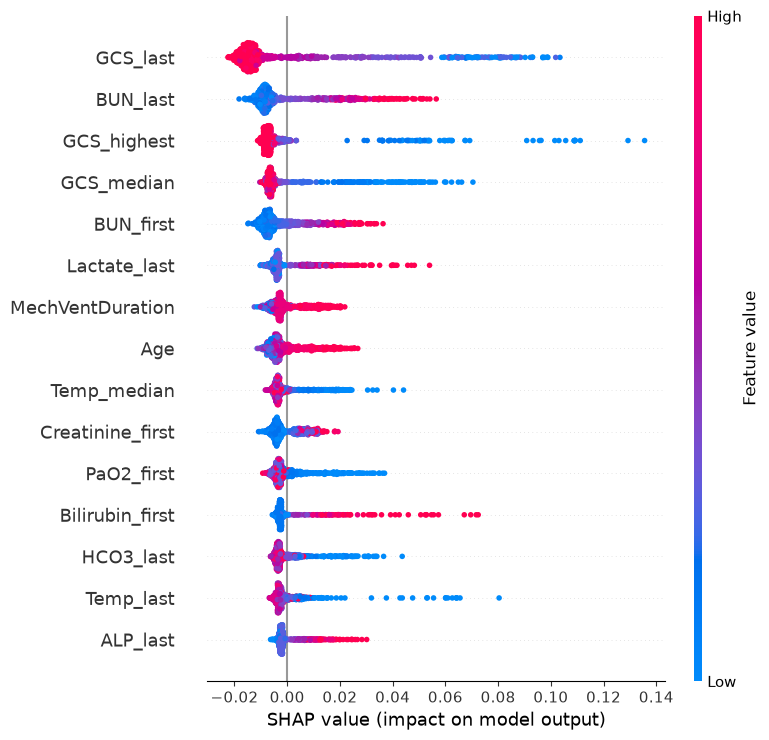

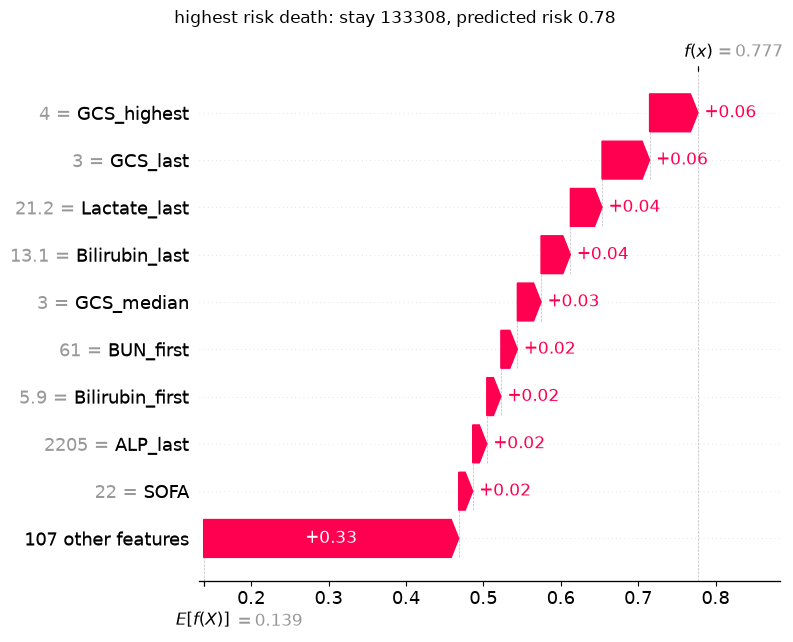

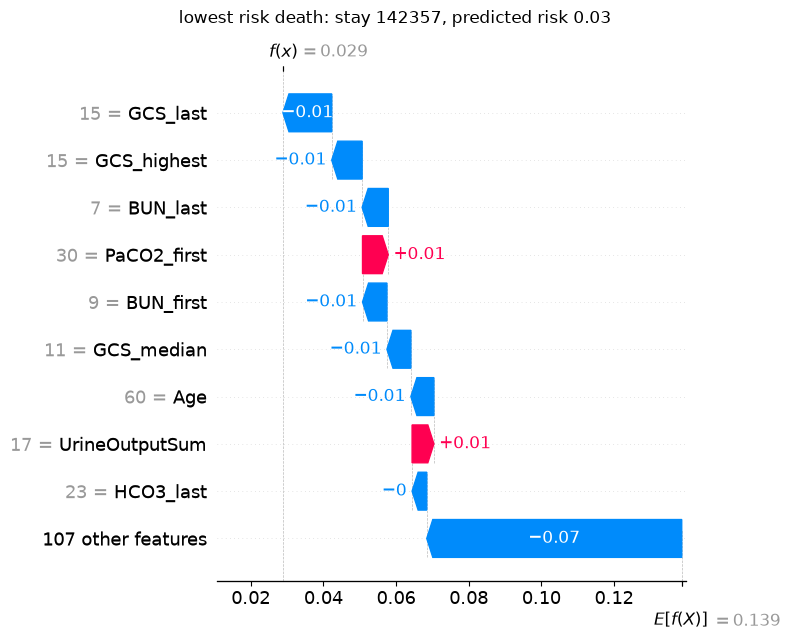

Focus patient 135576 (died): forest risk 0.55, tree 0 vote 0.30, SD across trees 0.39
SHAP reference value 0.139; top inputs by mean |SHAP|: GCS_last, BUN_last, GCS_highest


,step,question,death_rate_at_node
0,0,SOFA = 17.00 > 13.50,0.141
1,1,GCS_last = 8.00 <= 8.50,0.508
2,2,Creatinine_first = 6.50 > 1.70,0.658
3,3,DiasABP_highest = 94.00 > 80.50,0.796
4,4,LEAF: tree 0 votes this death rate,0.300


In [5]:
rf = models["random_forest"]
p_val = rf.predict_proba(X_val_t)[:, 1]

# Check 1: forest risk = mean of the tree votes
tree_votes = np.stack([t.predict_proba(X_val_t.to_numpy())[:, 1] for t in rf.estimators_])  # (trees, patients)
np.testing.assert_allclose(tree_votes.mean(axis=0), p_val, atol=1e-12)
tree_sd = tree_votes.std(axis=0)

# Check 2: SHAP reference + contributions = prediction
sv, shap_base = rf_shap(rf, X_val_t)
np.testing.assert_allclose(shap_base + sv.sum(axis=1), p_val, atol=1e-7)

top3 = np.argsort(-np.abs(sv), axis=1)[:, :3]
val_table = pd.DataFrame({
    "recordid": ICU.loc[idx_val, ID_COL].values,
    "died": y_val.values,
    "forest_risk": p_val.round(3),
    "tree_vote_sd": tree_sd.round(3),
    "top_3_drivers": [", ".join(f"{feat_names[j]} ({sv[i, j]:+.3f})" for j in top3[i]) for i in range(len(sv))],
    **{c: X.loc[idx_val, c].replace(-1, np.nan).values for c in ["Age", "SAPS-I", "GCS_last", "BUN_last"]},
})

# One patient through one tree: the death on which the trees disagree most
deaths = np.flatnonzero(y_val.values == 1)
focus = int(deaths[np.argmax(tree_sd[deaths])])
x, tree = X_val_t.to_numpy()[[focus]], rf.estimators_[0].tree_
path = []
for node in rf.estimators_[0].decision_path(x).indices:
    rate = float(tree.value[node, 0, 1] / tree.value[node, 0].sum())
    if tree.children_left[node] == -1:
        question = "LEAF: tree 0 votes this death rate"
    else:
        f, thr = tree.feature[node], tree.threshold[node]
        question = f"{feat_names[f]} = {x[0, f]:.2f} {'<=' if x[0, f] <= thr else '>'} {thr:.2f}"
    path.append({"step": len(path), "question": question, "death_rate_at_node": round(rate, 3)})
path_df = pd.DataFrame(path)

shap_imp = pd.DataFrame({"feature": feat_names, "mean_abs_shap": np.abs(sv).mean(axis=0)}).nlargest(15, "mean_abs_shap")
with wandb.init(project=PROJECT, name="04-under-the-hood", job_type="explain", tags=["explain"],
                config={**RF_PARAMS, "shap_method": "tree_path_dependent",
                        "focus_recordid": int(val_table.recordid[focus])}) as run:
    use_inputs(run)
    run.log({
        "val_predictions": wandb.Table(dataframe=val_table),
        "decision_path_tree0": wandb.Table(dataframe=path_df),
        "tree_votes_focus_patient": wandb.Histogram(tree_votes[:, focus]),
        "shap_importance": wandb.plot.bar(wandb.Table(dataframe=shap_imp), "feature", "mean_abs_shap",
                                          title="Mean |SHAP| (top 15)"),
        "shap_base_value": shap_base,
    })
    shap.summary_plot(sv, X_val_t, max_display=15, show=False, rng=np.random.default_rng(SEED))
    run.log({"shap_summary": wandb.Image(plt.gcf())})
    plt.show()
    for label, i in {"highest_risk_death": deaths[p_val[deaths].argmax()],
                     "lowest_risk_death": deaths[p_val[deaths].argmin()]}.items():
        shap.plots.waterfall(shap.Explanation(values=sv[i], base_values=shap_base, data=X_val_t.iloc[i].values,
                                              feature_names=feat_names), max_display=10, show=False)
        fig = plt.gcf()
        fig.suptitle(f"{label.replace('_', ' ')}: stay {val_table.recordid[i]}, predicted risk {p_val[i]:.2f}")
        fig.tight_layout()
        run.log({f"shap_waterfall_{label}": wandb.Image(fig)})
        plt.show()

print(f"Focus patient {val_table.recordid[focus]} (died): forest risk {p_val[focus]:.2f}, "
      f"tree 0 vote {tree_votes[0, focus]:.2f}, SD across trees {tree_sd[focus]:.2f}")
print(f"SHAP reference value {shap_base:.3f}; top inputs by mean |SHAP|: {', '.join(shap_imp.feature[:3])}")
path_df

**Read it:** for stay 135576, who died, the 300 trees disagree strongly (SD 0.39). Their average, 0.55, is the forest's risk. Tree 0 alone votes 0.30: the path table shows its four questions (SOFA, last GCS, creatinine, diastolic pressure) and the leaf's death rate. `death_rate_at_node` is the rate among the training stays that reached that node, before its question is answered

Across the validation set, the last and highest GCS and the last BUN have the largest average contributions. The lowest-risk death (stay 142357, predicted 0.03) shows the limit of a top-3 list: a normal GCS of 15 lowers its risk, but the 107 other inputs together lower it more. Both checks passed: tree votes average to the forest risk, and SHAP contributions add up to each prediction

## 6. Tune with a sweep

In a **sweep**, W&B chooses the settings: `wandb.sweep` registers the search space, then `wandb.agent` calls `sweep_trial` once per trial, with that trial's settings in `run.config`. The Bayesian search uses earlier trials to pick the next ones. Test patients never enter tuning

**In W&B:** open the sweep and add **Parallel coordinates** (settings → `val_pr`) and **Parameter importance** (target `val_pr`). A scatter of `fit_seconds` against `val_pr` shows cost and gain together; `overfit_gap_pr` compares training and validation scores

Judge the best gain against the seed spread from section 4. Validation guided the choice, so the best validation score is optimistic

In [6]:
sweep_config = {
    "method": "bayes",
    "metric": {"name": "val_pr", "goal": "maximize"},
    "parameters": {
        "n_estimators": {"values": [100, 200, 300, 500]},
        "max_depth": {"values": [0, 4, 8, 12, 16]},  # 0 = no depth limit
        "max_features": {"values": ["sqrt", "log2"]},
        "min_samples_leaf": {"values": [1, 3, 5, 10, 20]},
    },
}


def sweep_trial():
    with wandb.init(job_type="sweep", tags=["sweep"]) as run:
        cfg = run.config  # settings chosen by the sweep for this trial
        use_inputs(run)
        model = RandomForestClassifier(n_estimators=cfg.n_estimators, max_depth=cfg.max_depth or None,
                                       max_features=cfg.max_features, min_samples_leaf=cfg.min_samples_leaf,
                                       random_state=SEED, n_jobs=-1)
        t0 = perf_counter()
        model.fit(X_train_t, y_train)
        fit_seconds = perf_counter() - t0
        val = score(y_val, model.predict_proba(X_val_t)[:, 1])
        train_pr = average_precision_score(y_train, model.predict_proba(X_train_t)[:, 1])
        run.log({**{f"val_{k}": v for k, v in val.items()}, "train_pr": train_pr,
                 "overfit_gap_pr": train_pr - val["pr"], "fit_seconds": fit_seconds})


best_params, best_val_pr, sweep_id = dict(RF_PARAMS), results["random_forest"]["val_pr"], None
if ONLINE:
    sweep_id = wandb.sweep(sweep_config, project=PROJECT)
    wandb.agent(sweep_id, function=sweep_trial, count=10)
    # The agent leaves its sweep ID in the environment; clear it so the final run does not join the sweep
    for key in ("WANDB_SWEEP_ID", "WANDB_SWEEP_PARAM_PATH"):
        os.environ.pop(key, None)
    wandb.teardown()
    best = wandb.Api().sweep(f"{ENTITY}/{PROJECT}/{sweep_id}").best_run()  # read the result back from W&B
    print(f"Best trial {best.name}: val_pr {best.summary['val_pr']:.3f}, baseline {best_val_pr:.3f}")
    if best.summary["val_pr"] > best_val_pr:
        best_params = {k: best.config[k] for k in RF_PARAMS}
        best_params["max_depth"] = best_params["max_depth"] or None
        best_val_pr = float(best.summary["val_pr"])
else:
    print("Offline: sweep skipped; the final model uses the baseline settings")
print("Selected settings:", best_params)

Create sweep with ID: 3gkn7svn
Sweep URL: https://wandb.ai/idiazl/icu-wandb-mvp/sweeps/3gkn7svn
Best trial light-sweep-1: val_pr 0.488, baseline 0.488
Selected settings: {'n_estimators': 300, 'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 3}


## 7. Final model: test once, save and trace

The selected settings are refitted together with preprocessing, as one pipeline, on training plus validation patients. The pipeline is evaluated once on the 800 reserved test patients. The run saves it as a **model artifact** and declares the data and split as inputs, which closes the lineage chain: data and split → final run → model. A reload check confirms the saved file reproduces the predictions

**In W&B:** run `05-final-model` → **Overview** for `test_*` metrics and config, **Files** for the code snapshot and `requirements.txt` → **Artifacts** → `icu-rf-pipeline` → **Lineage**

To promote the model, link it to a Registry collection with `run.link_artifact(model_art, "wandb-registry-model/<collection>")`. An alias such as `candidate` is a label, not clinical approval

In [7]:
idx_trval = idx_train.append(idx_val)
final = Pipeline([("preprocess", make_preprocessor(num_cols, cat_cols)),
                  ("forest", RandomForestClassifier(**best_params, random_state=SEED, n_jobs=-1))])

with wandb.init(project=PROJECT, name="05-final-model", job_type="final", tags=["final"],
                config={**best_params, "selected_val_pr": best_val_pr, "source_sweep": sweep_id,
                        "trained_on": "train + validation"}) as run:
    use_inputs(run)
    final.fit(X.loc[idx_trval], y.loc[idx_trval])
    p_test = final.predict_proba(X.loc[idx_test])[:, 1]
    test = {f"test_{k}": v for k, v in score(y.loc[idx_test], p_test).items()}

    model_file = OUTPUT_DIR / "icu_rf_pipeline.joblib"
    joblib.dump(final, model_file)
    reload_gap = float(np.abs(joblib.load(model_file).predict_proba(X.loc[idx_test])[:, 1] - p_test).max())
    assert reload_gap < 1e-9, "The reloaded pipeline gives different predictions"
    run.log({**test, **curves(y.loc[idx_test], p_test, "test"), "reload_max_gap": reload_gap})

    model_art = wandb.Artifact("icu-rf-pipeline", type="model",
                               description="Teaching pipeline: hospital-death risk after 48 h in ICU",
                               metadata={**best_params, **test, "intended_use": "teaching only, no clinical validation"})
    model_art.add_file(str(model_file))
    run.log_artifact(model_art, aliases=["candidate"])
    run.log_code(".", name="icu-source", include_fn=lambda p: Path(p).name in {NOTEBOOK, "utils.py"})

print(f"Test: {len(idx_test)} stays, {int(y.loc[idx_test].sum())} deaths; reload gap {reload_gap:.1e}")
pd.Series(test).round(3)

Test: 800 stays, 111 deaths; reload gap 1.1e-16


test_auc      0.863
test_pr       0.536
test_brier    0.091
test_ece      0.047
dtype: float64

## 8. What W&B added

- **Traceability:** every score links to its data version, patient split, settings and code snapshot
- **Comparison:** baselines, repeated fits and sweep trials sit in one Runs table with the same metric names
- **Stability:** run groups separate forest randomness from patient selection
- **Transparency:** the `val_predictions` table makes every validation prediction inspectable, with its tree disagreement and top SHAP drivers
- **Reproducibility:** the final pipeline is a versioned artifact whose lineage reaches back to the raw data

**Wrap up in W&B:** create a **Report** from the project page with the baseline Runs table, the grouped repeat runs, the `val_predictions` table, the sweep panels and the model lineage. It tells this story with live panels and can be shared

**Limits:** one historical cohort, no external or clinical validation. Section 5 explains the baseline forest, not the refitted final model